In [2]:
!pip install -q sentence-transformers datasets rank_bm25 matplotlib pandas

In [3]:
# %% Cell 2: load SciFact (scientific claims + paper abstracts)
import numpy as np, pandas as pd, random, torch
from datasets import load_dataset

random.seed(42); np.random.seed(42); torch.manual_seed(42)

corpus_ds = load_dataset("BeIR/scifact", "corpus")["corpus"]
queries_ds = load_dataset("BeIR/scifact", "queries")["queries"]
qrels = load_dataset("BeIR/scifact-qrels")          # splits: train, test

corpus = {r["_id"]: (r["title"] + ". " + r["text"]).strip() for r in corpus_ds}
queries = {r["_id"]: r["text"] for r in queries_ds}

def build_rel(split):
    rel = {}
    for r in qrels[split]:
        if r["score"] > 0:
            rel.setdefault(str(r["query-id"]), set()).add(str(r["corpus-id"]))
    return rel

train_rel, test_rel = build_rel("train"), build_rel("test")
print(f"corpus={len(corpus)} train_queries={len(train_rel)} test_queries={len(test_rel)}")

doc_ids = list(corpus.keys())
doc_texts = [corpus[d] for d in doc_ids]
test_qids = [q for q in test_rel if q in queries]

README.md:   0%|          | 0.00/10.4k [00:00<?, ?B/s]

corpus/corpus-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.47MB            

corpus/corpus-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating corpus split:   0%|          | 0/5183 [00:00<?, ? examples/s]

queries/queries-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 65.0kB            

queries/queries-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (3 outputs left out)

test.tsv:   0%|          | 0.00/5.39k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/919 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/339 [00:00<?, ? examples/s]

corpus=5183 train_queries=809 test_queries=300


In [4]:
import torch; print(torch.cuda.is_available())

True


In [5]:
# %% Cell 3: metrics (Recall@5, MRR@10, nDCG@10), same code for every model

def evaluate_rankings(rankings):
    """rankings: dict qid -> list of doc_ids ranked best first"""
    rec5, mrr, ndcg = [], [], []
    for qid in test_qids:
        rel = test_rel[qid]
        ranked = rankings[qid][:10]
        rec5.append(len(set(ranked[:5]) & rel) / len(rel))
        rr = 0.0
        for i, d in enumerate(ranked):
            if d in rel:
                rr = 1.0 / (i + 1); break
        mrr.append(rr)
        dcg = sum(1.0 / np.log2(i + 2) for i, d in enumerate(ranked) if d in rel)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(rel), 10)))
        ndcg.append(dcg / idcg)
    return {"Recall@5": np.mean(rec5), "MRR@10": np.mean(mrr), "nDCG@10": np.mean(ndcg)}


In [6]:
# %% Cell 4: baseline 1, BM25 (keyword search)

from rank_bm25 import BM25Okapi

tok = lambda s: s.lower().split()
bm25 = BM25Okapi([tok(t) for t in doc_texts])
bm25_rank = {}
for qid in test_qids:
    scores = bm25.get_scores(tok(queries[qid]))
    bm25_rank[qid] = [doc_ids[i] for i in np.argsort(-scores)[:10]]
results = {"BM25 (keyword)": evaluate_rankings(bm25_rank)}
print(results)

{'BM25 (keyword)': {'Recall@5': np.float64(0.6208333333333333), 'MRR@10': np.float64(0.5326190476190475), 'nDCG@10': np.float64(0.5669746401043002)}}


In [7]:
# %% Cell 5: baseline 2, off-the-shelf embedding model (no fine-tuning)

from sentence_transformers import SentenceTransformer, losses, InputExample
from torch.utils.data import DataLoader

def dense_rank(model, q_prefix=""):
    d_emb = model.encode(doc_texts, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    q_emb = model.encode([q_prefix + queries[q] for q in test_qids], normalize_embeddings=True)
    sims = q_emb @ d_emb.T
    return {qid: [doc_ids[i] for i in np.argsort(-sims[k])[:10]] for k, qid in enumerate(test_qids)}

BASE = "BAAI/bge-small-en-v1.5"
QP = "Represent this sentence for searching relevant passages: "   # BGE query instruction
base_model = SentenceTransformer(BASE)
results["Off-the-shelf BGE-small"] = evaluate_rankings(dense_rank(base_model, QP))
print(results)

/tmp/ipykernel_1088/1684587717.py:3: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, losses, InputExample


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/81 [00:00<?, ?it/s]

{'BM25 (keyword)': {'Recall@5': np.float64(0.6208333333333333), 'MRR@10': np.float64(0.5326190476190475), 'nDCG@10': np.float64(0.5669746401043002)}, 'Off-the-shelf BGE-small': {'Recall@5': np.float64(0.764), 'MRR@10': np.float64(0.6725211640211641), 'nDCG@10': np.float64(0.7056756050898959)}}


In [8]:
# %% Cell 6: fine-tune on SciFact TRAIN split only (test split is never seen in training)

train_examples = []
for qid, rels in train_rel.items():
    if qid not in queries: continue
    for did in rels:
        train_examples.append(InputExample(texts=[QP + queries[qid], corpus[did]]))
print("training pairs:", len(train_examples))

model = SentenceTransformer(BASE)
loader = DataLoader(train_examples, shuffle=True, batch_size=32)
# In-batch negatives: every other document in the batch acts as a wrong answer.
loss = losses.MultipleNegativesRankingLoss(model)
model.fit(train_objectives=[(loader, loss)], epochs=4, warmup_steps=20,
          optimizer_params={"lr": 2e-5}, show_progress_bar=True)
model.save("scibot-sci-retriever")

results["Fine-tuned BGE-small (ours)"] = evaluate_rankings(dense_rank(model, QP))

training pairs: 919


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/81 [00:00<?, ?it/s]

                             Recall@5  MRR@10  nDCG@10
BM25 (keyword)                  0.621   0.533    0.567
Off-the-shelf BGE-small         0.764   0.673    0.706
Fine-tuned BGE-small (ours)     0.824   0.716    0.759


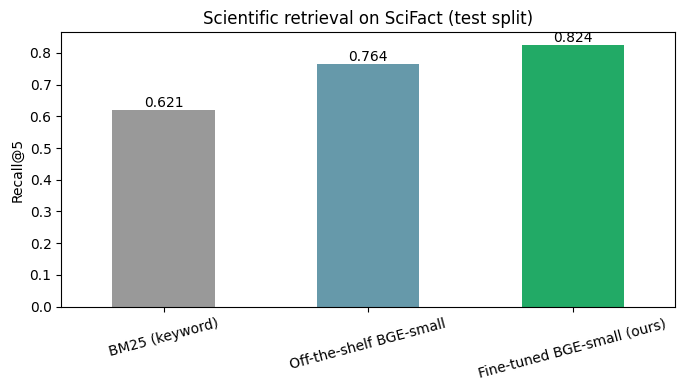

In [9]:
# %% Cell 7: results table + chart (this is your panel slide)

df = pd.DataFrame(results).T.round(3)
print(df)
df.to_csv("results.csv")

import matplotlib.pyplot as plt
ax = df["Recall@5"].plot(kind="bar", figsize=(7, 4), color=["#999", "#69a", "#2a6"], rot=15)
ax.set_ylabel("Recall@5"); ax.set_title("Scientific retrieval on SciFact (test split)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.savefig("results_chart.png", dpi=200)

In [10]:
!zip -r scibot-sci-retriever.zip scibot-sci-retriever
from google.colab import files
files.download("scibot-sci-retriever.zip")
files.download("results.csv")
files.download("results_chart.png")

  adding: scibot-sci-retriever/ (stored 0%)
  adding: scibot-sci-retriever/1_Pooling/ (stored 0%)
  adding: scibot-sci-retriever/1_Pooling/config.json (deflated 15%)
  adding: scibot-sci-retriever/config.json (deflated 52%)
  adding: scibot-sci-retriever/config_sentence_transformers.json (deflated 40%)
  adding: scibot-sci-retriever/README.md (deflated 66%)
  adding: scibot-sci-retriever/tokenizer_config.json (deflated 48%)
  adding: scibot-sci-retriever/sentence_bert_config.json (deflated 43%)
  adding: scibot-sci-retriever/model.safetensors (deflated 14%)
  adding: scibot-sci-retriever/modules.json (deflated 64%)
  adding: scibot-sci-retriever/2_Normalize/ (stored 0%)
  adding: scibot-sci-retriever/tokenizer.json (deflated 71%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import torch; print(torch.cuda.is_available())


True


In [12]:
# %% Cell 9: generic evaluation helpers (work for any dataset)

import numpy as np, pandas as pd, random, torch, gc
from datasets import load_dataset
from sentence_transformers import SentenceTransformer, losses, InputExample
from torch.utils.data import DataLoader

def metrics_for(rankings, qids, rel):
    rec5, mrr, ndcg = [], [], []
    for qid in qids:
        r = rel[qid]; ranked = rankings[qid][:10]
        rec5.append(len(set(ranked[:5]) & r) / len(r))
        rr = next((1.0 / (i + 1) for i, d in enumerate(ranked) if d in r), 0.0)
        mrr.append(rr)
        dcg = sum(1.0 / np.log2(i + 2) for i, d in enumerate(ranked) if d in r)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(r), 10)))
        ndcg.append(dcg / idcg)
    return {"Recall@5": np.mean(rec5), "MRR@10": np.mean(mrr), "nDCG@10": np.mean(ndcg)}

def eval_dense(model, d_ids, d_texts, qids, q_texts, rel, q_prefix=QP):
    d_emb = model.encode(d_texts, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    q_emb = model.encode([q_prefix + t for t in q_texts], normalize_embeddings=True)
    sims = q_emb @ d_emb.T
    rankings = {q: [d_ids[i] for i in np.argsort(-sims[k])[:10]] for k, q in enumerate(qids)}
    return metrics_for(rankings, qids, rel)


In [13]:
# %% Cell 10: SciFact, train 3 fresh models with different seeds, evaluate on the test split

sf_q_texts = [queries[q] for q in test_qids]
seed_rows = []
for seed in [1, 2, 3]:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = SentenceTransformer(BASE)
    ex = [InputExample(texts=[QP + queries[q], corpus[d]])
          for q, rels in train_rel.items() if q in queries for d in rels]
    dl = DataLoader(ex, shuffle=True, batch_size=32)
    m.fit(train_objectives=[(dl, losses.MultipleNegativesRankingLoss(m))],
          epochs=4, warmup_steps=20, optimizer_params={"lr": 2e-5}, show_progress_bar=False)
    res = eval_dense(m, doc_ids, doc_texts, test_qids, sf_q_texts, test_rel)
    res["seed"] = seed
    seed_rows.append(res); print(res)
    del m; gc.collect(); torch.cuda.empty_cache()

seed_df = pd.DataFrame(seed_rows).set_index("seed")
base_sf = results["Off-the-shelf BGE-small"]   # from Cell 5
print("\nSciFact, fine-tuned over 3 seeds")
print(seed_df.round(3))
summary_sf = pd.DataFrame({
    "Off-the-shelf": pd.Series(base_sf),
    "Fine-tuned mean": seed_df.mean(),
    "Fine-tuned std": seed_df.std(),
}).round(3)
print(summary_sf)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'train_runtime': '160.1', 'train_samples_per_second': '22.96', 'train_steps_per_second': '0.725', 'train_loss': '0.3111', 'epoch': '4'}
{'Recall@5': np.float64(0.8152777777777778), 'MRR@10': np.float64(0.7110648148148148), 'nDCG@10': np.float64(0.755324667614481), 'seed': 1}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'train_runtime': '159.3', 'train_samples_per_second': '23.07', 'train_steps_per_second': '0.728', 'train_loss': '0.3161', 'epoch': '4'}
{'Recall@5': np.float64(0.825), 'MRR@10': np.float64(0.7217936507936508), 'nDCG@10': np.float64(0.7644204038585231), 'seed': 2}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'train_runtime': '159.3', 'train_samples_per_second': '23.08', 'train_steps_per_second': '0.728', 'train_loss': '0.318', 'epoch': '4'}
{'Recall@5': np.float64(0.8116666666666666), 'MRR@10': np.float64(0.7134695767195768), 'nDCG@10': np.float64(0.7565101634047744), 'seed': 3}

SciFact, fine-tuned over 3 seeds
      Recall@5  MRR@10  nDCG@10
seed                           
1        0.815   0.711    0.755
2        0.825   0.722    0.764
3        0.812   0.713    0.757
          Off-the-shelf  Fine-tuned mean  Fine-tuned std
Recall@5          0.764            0.817           0.007
MRR@10            0.673            0.715           0.006
nDCG@10           0.706            0.759           0.005


In [14]:
# %% Cell 11: generalization, NFCorpus (a DIFFERENT domain), model never trained on it
nf_corpus_ds = load_dataset("BeIR/nfcorpus", "corpus")["corpus"]
nf_queries_ds = load_dataset("BeIR/nfcorpus", "queries")["queries"]
nf_qrels = load_dataset("BeIR/nfcorpus-qrels")["test"]

nf_corpus = {r["_id"]: (r["title"] + ". " + r["text"]).strip() for r in nf_corpus_ds}
nf_queries = {r["_id"]: r["text"] for r in nf_queries_ds}
nf_rel = {}
for r in nf_qrels:
    if r["score"] > 0:
        nf_rel.setdefault(str(r["query-id"]), set()).add(str(r["corpus-id"]))
nf_qids = [q for q in nf_rel if q in nf_queries]
nf_ids = list(nf_corpus.keys()); nf_texts = [nf_corpus[d] for d in nf_ids]
nf_q_texts = [nf_queries[q] for q in nf_qids]
print(f"NFCorpus: docs={len(nf_ids)} test_queries={len(nf_qids)}")


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

corpus/corpus-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.16MB            

corpus/corpus-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating corpus split:   0%|          | 0/3633 [00:00<?, ? examples/s]

queries/queries-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 80.9kB            

queries/queries-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (5 outputs left out)

Generating train split:   0%|          | 0/110575 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11385 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12334 [00:00<?, ? examples/s]

NFCorpus: docs=3633 test_queries=323


In [15]:
# `model` is the SciFact fine-tuned model from Cell 6; `base_model` is the untouched one.
nf_res = {
    "Off-the-shelf BGE-small": eval_dense(base_model, nf_ids, nf_texts, nf_qids, nf_q_texts, nf_rel),
    "Fine-tuned on SciFact (zero-shot on NFCorpus)": eval_dense(model, nf_ids, nf_texts, nf_qids, nf_q_texts, nf_rel),
}
nf_df = pd.DataFrame(nf_res).T.round(3)
print(nf_df)

                                               Recall@5  MRR@10  nDCG@10
Off-the-shelf BGE-small                           0.126   0.529    0.343
Fine-tuned on SciFact (zero-shot on NFCorpus)     0.136   0.550    0.360


In [26]:
# %% Cell 12: save and download everything
summary_sf.to_csv("scifact_3seed_summary.csv")
seed_df.to_csv("scifact_per_seed.csv")
nf_df.to_csv("nfcorpus_generalization.csv")
from google.colab import files
for f in ["scifact_3seed_summary.csv", "scifact_per_seed.csv", "nfcorpus_generalization.csv"]:
  files.download(f)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>